---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 2"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 5. Складові повторювачі, підсилювальні двійки, каскодні схеми</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>2.1. Складові повторювачі напруги на транзисторах: приклади реалізації, переваги та недоліки, призначення, розрахункові співвідношення</li>
  <li>2.2. Підсилювальні двійки: приклади реалізації, переваги та недоліки, призначення, розрахункові співвідношення</li>
  <li>2.3. Каскодні схеми підсилення: приклади реалізації, переваги та недоліки, призначення, розрахункові співвідношення</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 5 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Складові повторювачі напруги](#compound-followers)
    * [🔬 Інтерактивно: одиночний повторювач, Дарлінгтона і Шиклаї (PySpice)](#followers-interactive)
* [Підсилювальні двійки](#twins)
    * [🔬 Інтерактивно: двійка СК–СБ проти каскаду СЕ (PySpice)](#twin-interactive)
* [Каскодні схеми підсилення](#cascode)
    * [🔬 Інтерактивно: каскод проти каскаду СЕ (PySpice)](#cascode-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Складові повторювачі напруги <a class="anchor" id="compound-followers"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.1</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати будову і властивості складових транзисторів Дарлінгтона і Шиклаї
> - Розраховувати еквівалентний коефіцієнт передачі струму, вхідний і вихідний опори складового повторювача
> - Знати переваги і недоліки складових повторювачів та їхнє застосування

</div>

Звичайний емітерний повторювач має вхідний опір $\approx(1+\beta)R_н$, що для низькоомного навантаження (динамік, кабель, обмотка реле) недостатньо, а витоковий повторювач — великий вихідний опір $\approx 1/S$. **Складові повторювачі** поєднують кілька транзисторів так, щоб отримати і дуже великий вхідний, і малий вихідний опір.

### Складовий транзистор Дарлінгтона

Емітер першого транзистора VT1 з'єднано з базою другого VT2, колектори об'єднано. Струм емітера VT1 є струмом бази VT2:
$$I_{к} = \beta_1 I_б + \beta_2(1 + \beta_1)I_б \;\Rightarrow\; \beta_{екв} = \beta_1 + \beta_2 + \beta_1\beta_2 \approx \beta_1\beta_2 .$$
Повторювач на складовому транзисторі:
$$R_{вх} \approx \beta_1\beta_2 R_н,\qquad R_{вих} \approx \frac{r_{е2}}{1} + \frac{r_{е1}}{\beta_2} + \frac{R_c}{\beta_1\beta_2},\qquad K_u \approx 1 .$$
**Недоліки:** напруга база–емітер подвоюється ($\approx 1{,}2\ldots1{,}4$ В) — більший зсув рівня і втрати розмаху; напруга насичення не менша за $U_{бе2} + U_{кенас1} \approx 0{,}9$ В; повільне вимикання VT2 (заряд бази розсмоктується лише через VT1) — тому між базою і емітером VT2 вмикають резистор $R$ (кілька сотень ом — кілоом), який також задає мінімальний струм VT1 і стабілізує режим.

### Складовий транзистор Шиклаї (комплементарний)

Транзистори **різної провідності**: n-p-n VT1 керує базою p-n-p VT2, колектор VT2 з'єднано з емітером VT1. Пара поводиться як один n-p-n транзистор з
$$\beta_{екв} \approx \beta_1\beta_2,\qquad U_{бе.екв} = U_{бе1}\approx 0{,}65\text{ В}.$$
Переваги перед Дарлінгтоном: **лише одна** напруга $U_{бе}$ (менший зсув і краща термостабільність — вихідна напруга визначається переходом малопотужного VT1), лінійніша передавальна характеристика. Недолік — пара охоплена місцевим ЗЗ і схильна до самозбудження на високих частотах.

### Складовий повторювач ПТ + БТ

Витоковий повторювач на ПТ (вхідний опір — гігаоми) навантажено на емітерний повторювач (вихідний опір — одиниці ом). Застосування — вхідні каскади вимірювальних приладів і щупів, буфери п'єзодатчиків.

**Застосування складових повторювачів:** вихідні каскади підсилювачів потужності (комплементарні двотактні повторювачі на парах Дарлінгтона або Шиклаї), стабілізатори напруги (регулюючий транзистор), драйвери реле, двигунів, світлодіодів (мікросхеми ULN2003 — сім пар Дарлінгтона), буферні каскади.

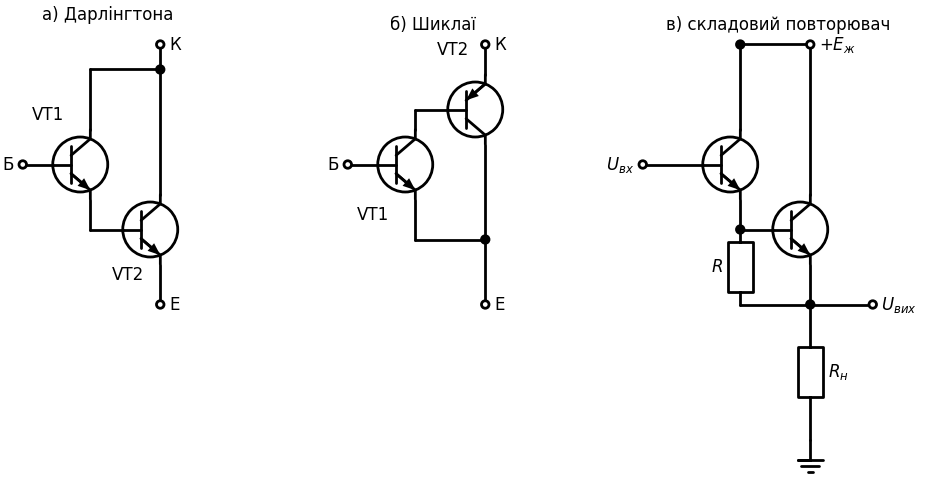

In [2]:
# Складові транзистори: а) Дарлінгтона; б) Шиклаї; в) повторювач на складовому транзисторі
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        # а) Дарлінгтон
        d += elm.Label().at((1.6, 5.4)).label('а) Дарлінгтона')
        d += elm.Dot(open=True).at((0, 2.5)).label('Б', loc='left'); d += W((0, 2.5), (0.6, 2.5))
        d += elm.BjtNpn(circle=True).theta(0).at((0.6, 2.5)).anchor('base'); d += elm.Label().at((0.4, 3.4)).label('VT1')
        d += W((1.35, 1.8), (1.35, 1.2)); d += W((1.35, 1.2), (2.0, 1.2))
        d += elm.BjtNpn(circle=True).theta(0).at((2.0, 1.2)).anchor('base'); d += elm.Label().at((2.0, 0.2)).label('VT2')
        d += W((1.35, 3.2), (1.35, 4.4)); d += W((1.35, 4.4), (2.75, 4.4)); d += W((2.75, 4.4), (2.75, 1.9)); d += elm.Dot().at((2.75, 4.4))
        d += W((2.75, 4.4), (2.75, 4.9)); d += elm.Dot(open=True).at((2.75, 4.9)).label('К', loc='right')
        d += W((2.75, 0.5), (2.75, -0.3)); d += elm.Dot(open=True).at((2.75, -0.3)).label('Е', loc='right')
        # б) Шиклаї
        ox = 6.5
        d += elm.Label().at((ox + 1.6, 5.4)).label('б) Шиклаї')
        d += elm.Dot(open=True).at((ox, 2.5)).label('Б', loc='left'); d += W((ox, 2.5), (ox + 0.6, 2.5))
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 0.6, 2.5)).anchor('base'); d += elm.Label().at((ox + 0.4, 1.4)).label('VT1')
        d += W((ox + 1.35, 3.2), (ox + 1.35, 3.6)); d += W((ox + 1.35, 3.6), (ox + 2.0, 3.6))
        d += elm.BjtPnp(circle=True).theta(0).at((ox + 2.0, 3.6)).anchor('base'); d += elm.Label().at((ox + 2.0, 4.7)).label('VT2')
        d += W((ox + 2.75, 4.3), (ox + 2.75, 4.9)); d += elm.Dot(open=True).at((ox + 2.75, 4.9)).label('К', loc='right')
        d += W((ox + 2.75, 2.9), (ox + 2.75, 1.0)); d += W((ox + 1.35, 1.8), (ox + 1.35, 1.0)); d += W((ox + 1.35, 1.0), (ox + 2.75, 1.0))
        d += elm.Dot().at((ox + 2.75, 1.0)); d += W((ox + 2.75, 1.0), (ox + 2.75, -0.3)); d += elm.Dot(open=True).at((ox + 2.75, -0.3)).label('Е', loc='right')
        # в) повторювач на складовому транзисторі з резистором R
        ox = 13
        d += elm.Label().at((ox + 2.0, 5.4)).label('в) складовий повторювач')
        d += W((ox + 1.35, 4.9), (ox + 2.75, 4.9)); d += elm.Dot(open=True).at((ox + 2.75, 4.9)).label('$+E_ж$', loc='right')
        d += elm.Dot(open=True).at((ox - 0.6, 2.5)).label('$U_{вх}$', loc='left'); d += W((ox - 0.6, 2.5), (ox + 0.6, 2.5))
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 0.6, 2.5)).anchor('base')
        d += W((ox + 1.35, 3.2), (ox + 1.35, 4.9)); d += elm.Dot().at((ox + 1.35, 4.9))
        d += W((ox + 1.35, 1.8), (ox + 1.35, 1.2)); d += W((ox + 1.35, 1.2), (ox + 2.0, 1.2)); d += elm.Dot().at((ox + 1.35, 1.2))
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 2.0, 1.2)).anchor('base')
        d += W((ox + 2.75, 1.9), (ox + 2.75, 4.9))
        d += elm.Resistor().at((ox + 1.35, 1.2)).to((ox + 1.35, -0.3)).label('$R$', loc='top'); d += W((ox + 1.35, -0.3), (ox + 2.75, -0.3))
        d += W((ox + 2.75, 0.5), (ox + 2.75, -0.3)); d += elm.Dot().at((ox + 2.75, -0.3))
        d += W((ox + 2.75, -0.3), (ox + 4.0, -0.3)); d += elm.Dot(open=True).at((ox + 4.0, -0.3)).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((ox + 2.75, -0.3)).to((ox + 2.75, -3.0)).label('$R_н$', loc='bottom'); d += elm.Ground().at((ox + 2.75, -3.0))

---
### 🔬 Інтерактивно: одиночний повторювач, Дарлінгтона і Шиклаї (PySpice) <a class="anchor" id="followers-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Три повторювачі ($\pm12$ В) працюють на однакове навантаження $R_н$ (між виходом і $-12$ В). Порівняйте вхідний опір, коефіцієнт передачі і постійний зсув вихідної напруги відносно входу (вхід — 0 В): у пари Дарлінгтона зсув подвоєний ($2U_{бе}$), у пари Шиклаї — одна $U_{бе}$.

</div>

In [3]:
# Порівняння повторювачів: R_вх, K_u, зсув рівня (PySpice)
def followers(Rl=1000.0):

    def foll(kind, Rl):
        c = Circuit(kind)
        c.include(spice_model('2n3904.lib'))
        c.model('QP', 'PNP', BF=150, IS=1e-14, VAF=80)
        c.V('cc', 'vcc', c.gnd, 12); c.V('ee', 'vee', c.gnd, -12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1, ac_magnitude=1)
        c.V('meas', 'src', 'b', 0)                                 # амперметр вхідного струму
        if kind == 'одиночний':
            c.BJT(1, 'vcc', 'b', 'out', model='Q2N3904')
        elif kind == 'Дарлінгтона':
            c.BJT(1, 'vcc', 'b', 'e1', model='Q2N3904'); c.BJT(2, 'vcc', 'e1', 'out', model='Q2N3904')
        else:                                                       # Шиклаї: n-p-n керує p-n-p
            c.BJT(1, 'c1', 'b', 'out', model='Q2N3904'); c.BJT(2, 'out', 'c1', 'vcc', model='QP')
        c.R('L', 'out', 'vee', Rl)
        a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=1e3, stop_frequency=1e3, number_of_points=1, variation='lin')
        op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
        K = abs(np.array(a['out'])[0]); Rin = 1 / abs(np.array(a.branches['vmeas'])[0])
        return K, Rin, float(np.array(op['out'])[0])

    kinds = ['одиночний', 'Дарлінгтона', 'Шиклаї']
    res = [foll(k, Rl) for k in kinds]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].bar(kinds, [r[1] / 1e3 for r in res], color=['#9E9E9E', '#2196F3', '#4CAF50']); ax[0].set_yscale('log')
    ax[0].set_ylabel('$R_{вх}$, кОм'); ax[0].set_title(f'Вхідний опір при $R_н$ = {Rl:.0f} Ом')
    for i, r in enumerate(res):
        ax[0].text(i, r[1] / 1e3, f'{r[1]/1e3:.0f}', ha='center', va='bottom')
    ax[1].bar(kinds, [-r[2] for r in res], color=['#9E9E9E', '#2196F3', '#4CAF50'])
    ax[1].set_ylabel('$U_{вх} - U_{вих}$, В'); ax[1].set_title('Постійний зсув рівня')
    for i, r in enumerate(res):
        ax[1].text(i, -r[2], f'{-r[2]:.2f} В', ha='center', va='bottom')
    plt.tight_layout(); plt.show()
    for k, r in zip(kinds, res):
        print(f'{k:12s}: K_u = {r[0]:.4f},  R_вх = {r[1]/1e3:9.0f} кОм,  R_вх/R_н = {r[1]/Rl:8.0f}')

interact(followers, Rl=widgets.FloatLogSlider(base=10, min=1.5, max=4, step=0.1, value=1000, description='Rн (Ом)'));

interactive(children=(FloatLogSlider(value=1000.0, description='Rн (Ом)', min=1.5), Output()), _dom_classes=('…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**$\beta_{екв} \approx \beta_1\beta_2$ — не означає, що складовий транзистор «у тисячі разів кращий».** Зростає лише коефіцієнт передачі струму. Напруга насичення, зсув рівня і швидкодія Дарлінгтона *гірші*, ніж в одиночного транзистора. Тому в ключових схемах складові транзистори поступаються MOSFET, а в лінійних — вибирають пару Шиклаї, коли важливі мала напруга зсуву і лінійність.

</div>

---

## Підсилювальні двійки <a class="anchor" id="twins"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.2</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Класифікувати підсилювальні двійки за типом каскадів, що їх утворюють
> - Пояснювати переваги двійок СК–СЕ, СК–СБ, СЕ–СК порівняно з одиночними каскадами
> - Розраховувати коефіцієнт підсилення і вхідний опір двійки

</div>

**Підсилювальна двійка** — два транзистори з безпосереднім (гальванічним) зв'язком, які утворюють єдиний каскад з властивостями, недосяжними для одного транзистора. Назву двійки утворюють зі схем увімкнення першого і другого транзисторів.

| Двійка | Склад | Властивості | Застосування |
|---|---|---|---|
| **СК–СЕ** | повторювач + підсилювач | великий $R_{вх} \approx\beta_1 h_{11е2}$, висока $K_u$; вхідний повторювач розв'язує джерело від ємності Міллера | проміжні каскади ОП (каскад підсилення напруги), підсилювачі з високоомним входом |
| **СК–СБ** (емітерно зв'язана пара) | повторювач керує емітером транзистора СБ | неінвертувальний, $K_u = \dfrac{g_m R_к}{2}$, широка смуга (немає ефекту Міллера у VT2), $R_{вх} \approx 2h_{11е}$ | широкосмугові і ВЧ-підсилювачі, обмежувачі, основа диференціального каскаду (тема 6) |
| **СЕ–СК** | підсилювач + повторювач | висока $K_u$ і малий $R_{вих}$ — підсилювач «майже ідеальний за напругою»; повторювач розв'язує $R_к$ від навантаження | вихідні вузли, драйвери навантажень |
| **СЕ–СБ** (каскод) | підсилювач + повторювач струму | широка смуга, великий $R_{вих}$ | див. наступний розділ |
| **СК–СК** | складовий повторювач | див. попередній розділ | буфери, вихідні каскади |

### Двійка СК–СЕ

Перший транзистор (повторювач) навантажено на вхідний опір другого:
$$R_{вх} \approx (1+\beta_1)\,h_{11е2},\qquad K_u \approx -g_{m2}(R_к\parallel R_н).$$
Вхідний опір зростає в $\beta_1$ разів при збереженні підсилення каскаду СЕ. Крім того, низький вихідний опір повторювача швидко перезаряджає ємність Міллера VT2, що розширює смугу при високоомному джерелі.

### Двійка СК–СБ (емітерно зв'язана)

Транзистори мають спільний резистор (або джерело струму) в колі емітерів. Сигнал у базу VT1 через емітерний повторювач передається на емітер VT2 (база VT2 заземлена за змінним струмом):
$$K_u = \frac{\beta R_к}{2h_{11е}} = \frac{g_mR_к}{2}\;(\text{без інверсії}),\qquad R_{вх} = 2h_{11е}\;(\text{при } R_е \gg r_е).$$
Ефекту Міллера немає ні в VT1 (повторювач з $K\approx 0{,}5$), ні в VT2 (СБ) — це один з найширокосмуговіших каскадів. При великому сигналі струм перемикається між транзисторами — двійка є точним **обмежувачем** з симетричною характеристикою.

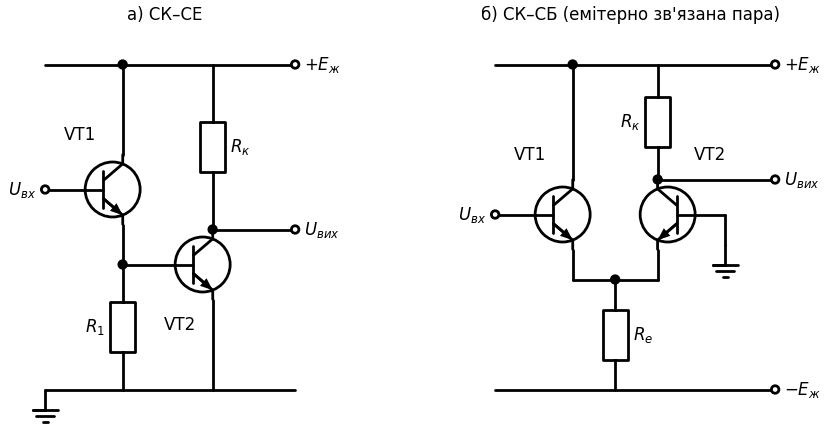

In [4]:
# Двійки: а) СК–СЕ; б) СК–СБ (емітерно зв'язана пара)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        # а) СК–СЕ
        d += elm.Label().at((2.3, 7.4)).label('а) СК–СЕ')
        d += W((0, 6.5), (5, 6.5)); d += elm.Dot(open=True).at((5, 6.5)).label('$+E_ж$', loc='right')
        d += W((0, 0), (5, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 4)).label('$U_{вх}$', loc='left'); d += W((0, 4), (0.8, 4))
        d += elm.BjtNpn(circle=True).theta(0).at((0.8, 4)).anchor('base'); d += elm.Label().at((0.6, 5.0)).label('VT1')
        d += W((1.55, 4.7), (1.55, 6.5)); d += elm.Dot().at((1.55, 6.5))
        d += W((1.55, 3.3), (1.55, 2.5)); d += elm.Dot().at((1.55, 2.5)); d += W((1.55, 2.5), (2.6, 2.5))
        d += elm.Resistor().at((1.55, 2.5)).to((1.55, 0)).label('$R_1$', loc='top')
        d += elm.BjtNpn(circle=True).theta(0).at((2.6, 2.5)).anchor('base'); d += elm.Label().at((2.6, 1.4)).label('VT2')
        d += W((3.35, 1.8), (3.35, 0))
        d += elm.Resistor().at((3.35, 6.5)).to((3.35, 3.2)).label('$R_к$', loc='bottom')
        d += elm.Dot().at((3.35, 3.2)); d += W((3.35, 3.2), (5, 3.2)); d += elm.Dot(open=True).at((5, 3.2)).label('$U_{вих}$', loc='right')
        # б) СК–СБ: VT1 — повторювач, VT2 — каскад СБ (база на сигнальній землі), спільний R_е до −E_ж
        ox = 9
        d += elm.Label().at((ox + 2.6, 7.4)).label("б) СК–СБ (емітерно зв'язана пара)")
        d += W((ox, 6.5), (ox + 5.6, 6.5)); d += elm.Dot(open=True).at((ox + 5.6, 6.5)).label('$+E_ж$', loc='right')
        d += W((ox, 0), (ox + 5.6, 0)); d += elm.Dot(open=True).at((ox + 5.6, 0)).label('$-E_ж$', loc='right')
        d += elm.Dot(open=True).at((ox, 3.5)).label('$U_{вх}$', loc='left'); d += W((ox, 3.5), (ox + 0.8, 3.5))
        d += elm.BjtNpn(circle=True).theta(0).at((ox + 0.8, 3.5)).anchor('base'); d += elm.Label().at((ox + 0.6, 4.6)).label('VT1')
        d += W((ox + 1.55, 4.2), (ox + 1.55, 6.5)); d += elm.Dot().at((ox + 1.55, 6.5))
        d += elm.BjtNpn(circle=True).theta(0).reverse().at((ox + 4.0, 3.5)).anchor('base'); d += elm.Label().at((ox + 4.4, 4.6)).label('VT2')
        d += W((ox + 4.0, 3.5), (ox + 4.6, 3.5)); d += W((ox + 4.6, 3.5), (ox + 4.6, 2.9)); d += elm.Ground().at((ox + 4.6, 2.9))
        d += W((ox + 1.55, 2.8), (ox + 1.55, 2.2)); d += W((ox + 3.25, 2.8), (ox + 3.25, 2.2)); d += W((ox + 1.55, 2.2), (ox + 3.25, 2.2))
        d += elm.Dot().at((ox + 2.4, 2.2))
        d += elm.Resistor().at((ox + 2.4, 2.2)).to((ox + 2.4, 0)).label('$R_е$', loc='bottom')
        d += elm.Resistor().at((ox + 3.25, 6.5)).to((ox + 3.25, 4.2)).label('$R_к$', loc='top')
        d += elm.Dot().at((ox + 3.25, 4.2))
        d += W((ox + 3.25, 4.2), (ox + 5.6, 4.2)); d += elm.Dot(open=True).at((ox + 5.6, 4.2)).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: двійка СК–СБ проти каскаду СЕ (PySpice) <a class="anchor" id="twin-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Емітерно зв'язана пара (VT1 — повторювач, VT2 — СБ, $R_е = 4{,}7$ кОм до $-12$ В, $R_к = 4{,}7$ кОм) і каскад СЕ з тим самим $R_к$ і струмом працюють від джерела з опором $R_c$. Пара має вдвічі менше підсилення ($g_mR_к/2$), не інвертує і має значно ширшу смугу. Праворуч — передавальна характеристика пари: симетричне обмеження при $|U_{вх}| \gtrsim 4\varphi_т \approx 100$ мВ.

</div>

In [5]:
# Двійка СК–СБ і каскад СЕ: АЧХ та передавальна характеристика пари
def twin(Rs=1000.0):
    def pair():
        c = Circuit('CC-CB pair')
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12); c.V('ee', 'vee', c.gnd, -12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.R('s', 'src', 'b1', Rs)
        c.BJT(1, 'vcc', 'b1', 'e', model='Q2N3904'); c.BJT(2, 'out', c.gnd, 'e', model='Q2N3904')
        c.R('e', 'e', 'vee', 4.7e3); c.R('c', 'vcc', 'out', 4.7e3); c.C('L', 'out', c.gnd, 2e-12)
        return c
    def ce():
        c = Circuit('CE')
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12); c.V('ee', 'vee', c.gnd, -12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.R('s', 'src', 'b1', Rs)
        c.BJT(1, 'out', 'b1', 'e', model='Q2N3904'); c.R('e', 'e', 'vee', 4.7e3 * 2); c.C('e', 'e', c.gnd, 1e-3)   # той самий струм, що в одному плечі пари
        c.R('c', 'vcc', 'out', 4.7e3); c.C('L', 'out', c.gnd, 2e-12)
        return c
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    for c, lab, col in ((ce(), 'СЕ', '#2196F3'), (pair(), 'СК–СБ', '#F44336')):
        f, v = ac(c, 1e3, 1e10, 30); g = np.abs(v['out']); g0 = g[0]
        fv = f[np.argmax(g < g0 / np.sqrt(2))]
        a1.semilogx(f, db(g), color=col, label=f'{lab}: K = {g0:.0f}, fв = {fv/1e6:.1f} МГц')
    a1.set_xlabel('Частота, Гц'); a1.set_ylabel('K, дБ'); a1.set_ylim(-10, 50); a1.legend(); a1.set_title(f'$R_c$ = {Rs:.0f} Ом')
    c = pair()
    a = c.simulator(temperature=25, nominal_temperature=25).dc(Vin=slice(-0.4, 0.4, 0.005))
    a2.plot(np.array(a.sweep) * 1e3, np.array(a['out']), color='#F44336')
    a2.set_xlabel('$U_{вх}$, мВ'); a2.set_ylabel('$U_{вих}$, В'); a2.set_title('Передавальна характеристика пари СК–СБ')
    plt.tight_layout(); plt.show()

interact(twin, Rs=widgets.FloatLogSlider(base=10, min=1.5, max=4, step=0.1, value=1000, description='Rc (Ом)'));

interactive(children=(FloatLogSlider(value=1000.0, description='Rc (Ом)', min=1.5), Output()), _dom_classes=('…

---

## Каскодні схеми підсилення <a class="anchor" id="cascode"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 2.3</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати будову каскоду СЕ–СБ (СВ–СЗ) і роль кожного транзистора
> - Розраховувати $K_u$, $R_{вх}$, $R_{вих}$ каскоду
> - Пояснювати, чому каскод усуває ефект Міллера і має великий вихідний опір

</div>

**Каскод** — послідовне (за постійним струмом — «стовпчиком») з'єднання каскаду СЕ (VT1) і каскаду СБ (VT2): колектор VT1 навантажено безпосередньо на емітер VT2, база VT2 має фіксований потенціал і заземлена за змінним струмом. Колекторний струм VT1 майже без змін ($\alpha \approx 1$) передається в колектор VT2 і далі в навантаження $R_к$.

### Основні співвідношення
$$K_u = -\frac{\alpha_2\beta_1(R_к\parallel R_н)}{h_{11е1}} \approx -g_{m1}(R_к\parallel R_н),\qquad R_{вх} = R_б\parallel h_{11е1}$$
— як у каскаду СЕ. Але навантаженням VT1 є малий вхідний опір каскаду СБ $r_{е2} \approx 1/g_{m2}$, тому коефіцієнт підсилення **самого VT1** за напругою $\approx -g_{m1}r_{е2} \approx -1$.

**Чому смуга ширша.** Ємність колекторного переходу VT1 $C_{к1}$ перераховується на вхід з коефіцієнтом Міллера $1 + |K_{u1}| \approx 2$, а не $1 + |K_u|$ (сотні). Транзистор VT2 у схемі СБ ефекту Міллера не має. Тому верхня гранична частота каскоду в рази (до десятків разів) вища, ніж у каскаду СЕ з тим самим підсиленням.

**Вихідний опір.** Вихідний опір транзистора СБ, у колі емітера якого стоїть великий опір $r_{к1}$:
$$R_{вих.тр} \approx r_{к2}(1 + g_{m2}(r_{к1}\parallel r_{бе2})) \approx \beta_2 r_{к2}$$
— у $\beta$ разів більше, ніж у одиночного транзистора. Тому каскод — основа **прецизійних джерел струму і струмових дзеркал** (тема 6) та каскадів з активним навантаженням з дуже великим підсиленням.

**Інші переваги:** напруга на колекторі VT1 зафіксована — немає ефекту Ерлі на VT1; великий розмах вихідної напруги на високовольтному VT2 (відеопідсилювачі); слабкий зв'язок виходу з входом — висока стійкість ВЧ-підсилювачів (малий параметр $y_{12}$).

**Недоліки:** потрібна додаткова напруга живлення (два транзистори «стовпчиком») — менший розмах при низькому живленні; додаткове коло зміщення бази VT2.

**Різновиди:** каскод на ПТ (СВ–СЗ) — малошумні ВЧ-підсилювачі тюнерів; двозатворні МДН-транзистори (вбудований каскод); **складений (folded) каскод** з VT2 протилежної провідності — у вхідних каскадах ОП з низьким живленням.

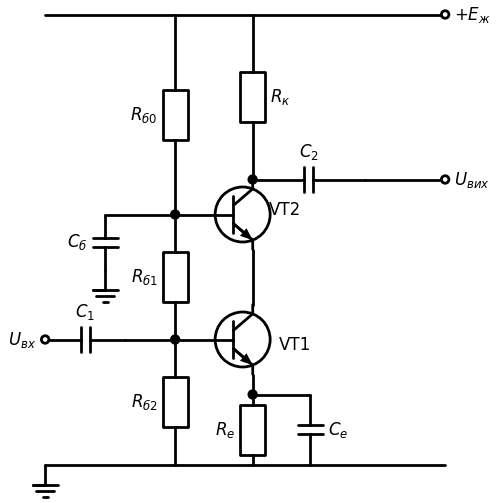

In [6]:
# Каскод СЕ–СБ: VT1 — каскад СЕ, VT2 — каскад СБ (база заземлена за змінним струмом через C_б)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 9), (8, 9)); d += elm.Dot(open=True).at((8, 9)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 2.5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 2.5)).to((1.6, 2.5)).label('$C_1$')
        d += W((1.6, 2.5), (3.4, 2.5)); d += elm.Dot().at((2.6, 2.5))
        d += elm.Resistor().at((2.6, 2.5)).to((2.6, 0)).label('$R_{б2}$', loc='top')
        d += elm.BjtNpn(circle=True).theta(0).at((3.4, 2.5)).anchor('base'); d += elm.Label().at((4.9, 2.5)).label('VT1')
        d += W((4.15, 1.8), (4.15, 1.4)); d += elm.Dot().at((4.15, 1.4))
        d += elm.Resistor().at((4.15, 1.4)).to((4.15, 0)).label('$R_е$', loc='top')
        d += W((4.15, 1.4), (5.3, 1.4)); d += elm.Capacitor().at((5.3, 1.4)).to((5.3, 0)).label('$C_е$', loc='bottom')
        d += W((4.15, 3.2), (4.15, 4.3))
        d += elm.BjtNpn(circle=True).theta(0).at((3.4, 5.0)).anchor('base'); d += elm.Label().at((4.9, 5.0)).label('VT2')
        d += W((3.4, 5.0), (2.6, 5.0)); d += elm.Dot().at((2.6, 5.0))
        d += elm.Resistor().at((2.6, 5.0)).to((2.6, 2.5)).label('$R_{б1}$', loc='top')
        d += elm.Resistor().at((2.6, 9)).to((2.6, 5.0)).label('$R_{б0}$', loc='top')
        d += W((2.6, 5.0), (1.2, 5.0)); d += elm.Capacitor().at((1.2, 5.0)).to((1.2, 3.9)).label('$C_б$', loc='top')
        d += elm.Ground().at((1.2, 3.9))
        d += elm.Resistor().at((4.15, 9)).to((4.15, 5.7)).label('$R_к$', loc='bottom')
        d += elm.Dot().at((4.15, 5.7))
        d += elm.Capacitor().at((4.15, 5.7)).to((6.4, 5.7)).label('$C_2$')
        d += W((6.4, 5.7), (8, 5.7)); d += elm.Dot(open=True).at((8, 5.7)).label('$U_{вих}$', loc='right')

Одне коло зміщення (дільник $R_{б0}, R_{б1}, R_{б2}$) задає напругу баз обох транзисторів; конденсатор $C_б$ заземлює базу VT2 за змінним струмом, $C_е$ шунтує $R_е$.

---
### 🔬 Інтерактивно: каскод проти каскаду СЕ (PySpice) <a class="anchor" id="cascode-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад СЕ і каскод (однаковий струм ≈1,4 мА, $R_к = 4{,}7$ кОм, ємність навантаження $C_н$) від джерела з опором $R_c$. Підсилення майже однакове, а смуга каскоду — в рази ширша. Збільшуйте $R_c$: у каскаду СЕ смуга різко звужується (ефект Міллера), у каскоду — значно менше.

</div>

In [7]:
# Каскад СЕ і каскод СЕ–СБ: АЧХ (PySpice)
def cascode(Rs=1000.0, Cl_pF=2.0):
    def build(kind):
        c = Circuit(kind)
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1); c.R('s', 'src', 'sx', Rs)
        c.C(1, 'sx', 'b', 10e-6); c.R('b1', 'vcc', 'b', 47e3); c.R('b2', 'b', c.gnd, 10e3)
        c.BJT(1, 'x', 'b', 'e', model='Q2N3904'); c.R('e', 'e', c.gnd, 1e3); c.C('e', 'e', c.gnd, 100e-6)
        if kind == 'каскод':
            c.R('b3', 'vcc', 'b2', 33e3); c.R('b4', 'b2', c.gnd, 33e3); c.C('b2', 'b2', c.gnd, 100e-6)
            c.BJT(2, 'out', 'b2', 'x', model='Q2N3904')
        else:
            c.R('x', 'x', 'out', 1e-3)
        c.R('c', 'vcc', 'out', 4.7e3); c.C('L', 'out', c.gnd, Cl_pF * 1e-12)
        return c
    fig, ax = plt.subplots(figsize=(9, 4))
    for kind, col in (('СЕ', '#2196F3'), ('каскод', '#F44336')):
        f, v = ac(build(kind), 1e3, 1e10, 30); g = np.abs(v['out']); g0 = g[5]
        fv = f[np.argmax((g < g0 / np.sqrt(2)) & (f > 1e4))]
        ax.semilogx(f, db(g), color=col, label=f'{kind}: K = {g0:.0f}, fв = {fv/1e6:.2f} МГц'); ax.axvline(fv, color=col, ls=':', lw=1)
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('K, дБ'); ax.set_ylim(-20, 50); ax.legend()
    ax.set_title(f'$R_c$ = {Rs:.0f} Ом, $C_н$ = {Cl_pF:.0f} пФ')
    plt.tight_layout(); plt.show()

interact(cascode,
         Rs=widgets.FloatLogSlider(base=10, min=1.5, max=4, step=0.1, value=1000, description='Rc (Ом)'),
         Cl_pF=widgets.FloatSlider(min=1, max=50, step=1, value=2, description='Cн (пФ)'));

interactive(children=(FloatLogSlider(value=1000.0, description='Rc (Ом)', min=1.5), FloatSlider(value=2.0, des…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Каскод не збільшує підсилення порівняно з каскадом СЕ з тим самим $R_к$.** $K_u \approx -g_{m1}R_к$ в обох схемах. Каскод виграє в **смузі** (немає ефекту Міллера), **вихідному опорі** та **розв'язці виходу від входу**. Велике підсилення каскод дає лише з високоомним (активним) навантаженням, де його великий $R_{вих}$ стає визначальним.

</div>

---
### ⚡ Практичне застосування: складові транзистори, двійки і каскоди в мікросхемах

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Де використовується |
|---|---|
| Пара Дарлінгтона | ULN2003/ULN2803 (драйвери реле і двигунів), силові транзистори TIP120/TIP142, вихідні каскади підсилювачів потужності |
| Пара Шиклаї | квазікомплементарні вихідні каскади звукових підсилювачів, стабілізатори з малим падінням напруги |
| СК–СЕ | проміжний каскад ОП μA741 (VT16–VT17) |
| СК–СБ | вхідний каскад μA741 (n-p-n повторювачі + латеральні p-n-p у схемі СБ), широкосмугові підсилювачі, обмежувачі ПЧ |
| Каскод | малошумні підсилювачі ВЧ (LNA), відеопідсилювачі, складений каскод у вхідних каскадах ОП, прецизійні джерела струму |

</div>

---
### ✅ Питання для самоперевірки: складові повторювачі, двійки, каскоди

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому у пари Дарлінгтона $\beta_{екв} \approx \beta_1\beta_2$?</summary>

> **Відповідь:** Емітерний струм VT1, що дорівнює $(1+\beta_1)I_б$, є струмом бази VT2, який підсилює його ще в $\beta_2$ разів.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чим пара Шиклаї краща за пару Дарлінгтона?</summary>

> **Відповідь:** Одна напруга $U_{бе}$ замість двох (менший зсув, краща термостабільність), вища лінійність; поведінку визначає малопотужний VT1.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Навіщо в парі Дарлінгтона резистор між базою і емітером VT2?</summary>

> **Відповідь:** Він прискорює розсмоктування заряду бази VT2 при вимиканні, відводить зворотний струм VT1 і задає мінімальний робочий струм VT1.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Чому двійка СК–СБ широкосмугова?</summary>

> **Відповідь:** Жоден з транзисторів не має ефекту Міллера: VT1 — повторювач, VT2 — каскад СБ.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чим каскод кращий за каскад СЕ?</summary>

> **Відповідь:** Ширша смуга (VT1 навантажено на малий $r_{е2}$, $|K_{u1}| \approx 1$), значно більший вихідний опір, розв'язка виходу і входу; підсилення — таке саме.

</details>

---
### 📝 Задачі для самостійного розв'язання: складові схеми


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Пара Дарлінгтона з $\beta_1 = 100$, $\beta_2 = 50$ живить навантаження 8 Ом струмом 2 А. Який потрібен струм бази? Який вхідний опір повторювача?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $\beta_{екв} \approx 5150$; $I_б \approx 0{,}39$ мА; $R_{вх} \approx 5150\cdot8 \approx 41$ кОм.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Каскод: $I_{к} = 1$ мА, $R_к = 10$ кОм, $\beta = 150$, $C_{к} = 3$ пФ. Порівняйте вхідну ємність Міллера каскаду СЕ та каскоду.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $g_m = 38{,}5$ мА/В; СЕ: $|K_u| = 385$, $C_M = 3\cdot386 \approx 1{,}16$ нФ. Каскод: $|K_{u1}| \approx 1$, $C_M \approx 6$ пФ — майже у 200 разів менше.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Двійка СК–СБ: $I_{е1} = I_{е2} = 0{,}5$ мА, $R_к = 10$ кОм, $\beta = 100$. Знайдіть $K_u$ і $R_{вх}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $g_m = 19{,}2$ мА/В; $K_u = g_mR_к/2 \approx 96$; $h_{11е} = \beta/g_m = 5{,}2$ кОм; $R_{вх} \approx 10{,}4$ кОм.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Ключові співвідношення |
|---|---|
| Дарлінгтона | $\beta_{екв} \approx \beta_1\beta_2$, $U_{бе.екв} \approx 2U_{бе}$, $R_{вх} \approx \beta_1\beta_2R_н$ |
| Шиклаї | $\beta_{екв} \approx \beta_1\beta_2$, $U_{бе.екв} = U_{бе1}$ |
| СК–СЕ | $R_{вх} \approx \beta_1h_{11е2}$, $K_u \approx -g_{m2}R_к$ |
| СК–СБ | $K_u = g_mR_к/2$ (без інверсії), $R_{вх} = 2h_{11е}$, широка смуга |
| Каскод СЕ–СБ | $K_u \approx -g_{m1}R_к$, $C_M \approx 2C_{к1}$, $R_{вих.тр} \approx \beta r_к$ |

**Головні висновки.** Комбінуючи два транзистори з безпосереднім зв'язком, отримують каскади з властивостями, недосяжними для одного транзистора: дуже великий $\beta$ і вхідний опір (складові транзистори), поєднання великого $R_{вх}$ з високим підсиленням (СК–СЕ), широку смугу без інверсії (СК–СБ), широку смугу і великий вихідний опір (каскод). Ці «цеглинки» становлять основу інтегральних підсилювачів, зокрема ОП.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Gray P. R., Hurst P. J., Lewis S. H., Meyer R. G. Analysis and Design of Analog Integrated Circuits. — 5th ed. — Wiley, 2009.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 4. Каскади СС, СБ, СЗ. Корекція АЧХ](Тема_04_Каскади_СС_СБ_СЗ_та_корекція_АЧХ.ipynb) &nbsp;|&nbsp; [Тема 6. Джерела струму, струмові дзеркала, диференціальні каскади](Тема_06_Джерела_струму_та_диференціальні_каскади.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*